## Historical Billboard Hot 100 trends and returns

This notebook describes chart persistence, repeat entries, and changes across broad historical periods. It uses the cleaned Billboard data and leaves the original file unchanged.

### Definitions and limits

A chart run is a continuous sequence of weekly records for the same song and artist, allowing at most seven days between chart dates. A return is a later run after a gap greater than seven days. This is a practical dataset-based definition; it does not distinguish a true commercial comeback from chart-recording gaps or changes in title/artist credit.

The data does not include release dates. “Song age” therefore means time since first observed Hot 100 appearance only when explicitly used as a proxy, not time since release. Period comparisons count chart records within each period; songs crossing period boundaries are truncated, and the latest period is right-censored.

##### Load and prepare the Billboard data

In [22]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path('../data/cleaned/billboard_cleaned.csv')
billboard = pd.read_csv(DATA_PATH, parse_dates=['date'], low_memory=False)

billboard['rank'] = pd.to_numeric(billboard['rank'], errors='coerce')

# Remove rows without the information needed for this analysis.
billboard = billboard.dropna(subset=['date', 'song', 'artist', 'rank']).copy()

# Put each song and artist together in date order before checking chart gaps.
billboard = billboard.sort_values(['song', 'artist', 'date']).reset_index(drop=True)

# Show the size and date coverage of the data we loaded.
print(f'{len(billboard):,} chart rows')
print(f"{billboard['date'].min():%Y-%m-%d} to {billboard['date'].max():%Y-%m-%d}")
print(f"{billboard[['song', 'artist']].drop_duplicates().shape[0]:,} distinct song/artist credits")

355,758 chart rows
1958-07-30 to 2026-09-30
32,688 distinct song/artist credits


##### Identify continuous chart runs and returns

In [23]:
song_artist = ['song', 'artist']

# number of days since this same song and artist were charted before.
billboard['gap_days'] = billboard.groupby(song_artist)['date'].diff().dt.days

# start a new chart run when this is the first chart record or the gap is over a week.
billboard['starts_new_run'] = billboard['gap_days'].isna() | billboard['gap_days'].gt(7)

# number the chart runs separately for each song and artist.
billboard['run_number'] = billboard.groupby(song_artist)['starts_new_run'].cumsum()

# summarize each run: start/end dates, how many chart dates, and best (lowest) rank.
runs = (billboard.groupby(song_artist + ['run_number'], as_index=False)
        .agg(start_date=('date', 'min'), end_date=('date', 'max'),
             chart_weeks=('date', 'nunique'), best_rank=('rank', 'min')))

# summarize each song/artist credit across its full history.
song_summary = (billboard.groupby(song_artist, as_index=False)
                .agg(first_chart_date=('date', 'min'), last_chart_date=('date', 'max'),
                     chart_weeks=('date', 'nunique'), best_rank=('rank', 'min'),
                     chart_runs=('run_number', 'nunique')))

# A run numbered 2 or higher means the song returned after a gap.
print(f"Distinct song/artist credits: {len(song_summary):,}")
print(f"Credits with multiple runs: {(song_summary['chart_runs'] > 1).sum():,}")
print(f"Later runs after a gap: {(runs['run_number'] > 1).sum():,}")

# Display the ten latest returns so we can inspect real examples.
display(runs[runs['run_number'] > 1].sort_values('start_date').tail(10))

Distinct song/artist credits: 32,688
Credits with multiple runs: 2,784
Later runs after a gap: 3,715


,song,artist,run_number,start_date,end_date,chart_weeks,best_rank
24639,Ran To Atlanta,Drake Featuring Future & Molly Santana,2,2026-09-16,2026-09-16,1,93
18022,Less,Olivia Rodrigo,2,2026-09-16,2026-09-16,1,96
20239,Matadora,Karol G,2,2026-09-16,2026-09-16,1,98
26027,Say So,Dan + Shay,2,2026-09-23,2026-09-30,2,89
5192,California Girls,Future,2,2026-09-23,2026-09-23,1,95
26285,September,"""Earth, Wind & Fire""",2,2026-09-30,2026-09-30,1,45
21518,My Way,Riley Green,3,2026-09-30,2026-09-30,1,60
17456,Kingdom Of Fear,Cameron Whitcomb,5,2026-09-30,2026-09-30,1,100
8320,Dope Girl,Rod Wave,2,2026-09-30,2026-09-30,1,95
19794,Lush Life,Zara Larsson,4,2026-09-30,2026-09-30,1,42


#### Compare broad periods

In [24]:
# each tuple sets a period label and its start and end dates.
periods = [
    ('1958–1992', '1958-01-01', '1992-12-31'),
    ('1993–2008', '1993-01-01', '2008-12-31'),
    ('2009–2019', '2009-01-01', '2019-12-31'),
    ('2020–2026*', '2020-01-01', '2026-12-31'),
]

period_rows = []

for label, start, end in periods:
    # Keep only chart records whose dates fall within this period.
    part = billboard[billboard['date'].between(start, end)]

    # Count chart weeks and find best rank for each song/artist in this period.
    per_song = part.groupby(song_artist).agg(
        chart_weeks=('date', 'nunique'), best_rank=('rank', 'min'))

    # Save a few simple measurements so we can compare the periods.
    period_rows.append({
        'period': label,
        'chart_rows': len(part),
        'distinct_song_artist_credits': len(per_song),
        'median_chart_weeks_in_period': per_song['chart_weeks'].median(),
        'one_week_share': (per_song['chart_weeks'].eq(1).mean() * 100),
        'credits_reaching_top_10': int(per_song['best_rank'].le(10).sum()),
    })

# Turn our saved measurements into a table and display rounded values.
period_summary = pd.DataFrame(period_rows)
display(period_summary.round(1))

,period,chart_rows,distinct_song_artist_credits,median_chart_weeks_in_period,one_week_share,credits_reaching_top_10
0,1958–1992,179658,18306,9.0,3.1,3367
1,1993–2008,83500,5403,16.0,4.1,948
2,2009–2019,57300,5001,8.0,27.1,594
3,2020–2026*,35300,4418,2.0,38.8,434


#### Visualize chart persistence and repeat runs

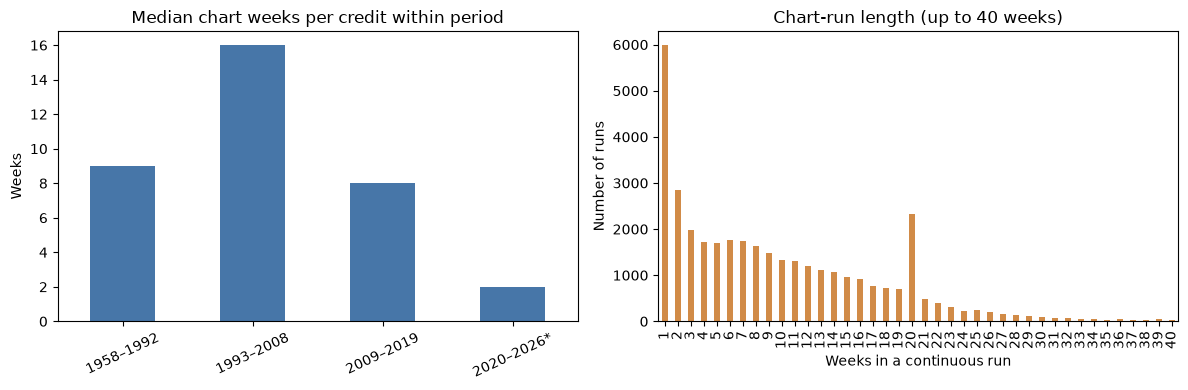

Share of all chart runs longer than 40 weeks: 0.77 %


In [25]:
# Make a chart area with two plots side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot the typical (median) number of chart weeks in each historical period.
period_summary.plot(x='period', y='median_chart_weeks_in_period', kind='bar',
                    ax=axes[0], legend=False, color='#4776A8')
axes[0].set_title('Median chart weeks per credit within period')
axes[0].set_ylabel('Weeks')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=25)

# Count chart runs of each length, showing lengths up to 40 weeks.
run_counts = runs.groupby('chart_weeks').size().sort_index()
run_counts[run_counts.index <= 40].plot(kind='bar', ax=axes[1], color='#D18B47')
axes[1].set_title('Chart-run length (up to 40 weeks)')
axes[1].set_xlabel('Weeks in a continuous run')
axes[1].set_ylabel('Number of runs')

# Tidy the spacing and show both plots.
plt.tight_layout()
plt.show()

# Calculate how many runs lasted longer than 40 weeks.
long_run_share = (runs['chart_weeks'] > 40).mean() * 100
print('Share of all chart runs longer than 40 weeks:', round(long_run_share, 2), '%')

#### Inspect older songs that returned

This list is a review aid: it shows credits whose later chart run began at least ten years after their first observed appearance. It does not establish release age or identify what caused a return.

In [26]:
# Keep only song/artist credits that have more than one separate chart run.
first_dates = song_summary[song_summary['chart_runs'] > 1][song_artist + ['first_chart_date']]

# Add the first observed chart date to each later run.
return_examples = runs[runs['run_number'] > 1].merge(first_dates, on=song_artist, how='left')

# Estimate years between the first observed chart date and the later return.
# This is not the song's real age because release dates are not in this dataset.
return_examples['years_since_first_observed'] = (
    (return_examples['start_date'] - return_examples['first_chart_date']).dt.days / 365.25)

# Keep returns that are at least ten years after the first chart appearance.
long_gap_returns = return_examples[return_examples['years_since_first_observed'] >= 10]

# Show up to 25 recent examples for a person to review.
display(long_gap_returns.sort_values('start_date', ascending=False)[
    song_artist + ['first_chart_date', 'start_date', 'chart_weeks',
                   'best_rank', 'years_since_first_observed']].head(25))
print('Later runs at least 10 years after first observed chart date:', len(long_gap_returns))

,song,artist,first_chart_date,start_date,chart_weeks,best_rank,years_since_first_observed
2737,September,"""Earth, Wind & Fire""",1978-11-15,2026-09-30,1,45,47.874059
1983,Lush Life,Zara Larsson,2016-07-27,2026-09-30,1,42,10.176591
1607,Islands In The Stream,Kenny Rogers Duet With Dolly Parton,1983-08-24,2026-09-02,1,26,43.025325
125,9 To 5,Dolly Parton,1980-11-26,2026-09-02,2,18,45.765914
1690,Jolene,Dolly Parton,1974-01-23,2026-09-02,3,16,52.607803
1506,I Will Always Love You,Dolly Parton,1982-07-28,2026-09-02,2,27,44.098563
1310,Here You Come Again,Dolly Parton,1977-10-12,2026-09-02,1,44,48.889802
3603,Wonderwall,Oasis,1996-01-24,2026-07-22,3,27,30.491444
2382,Party In The U.S.A.,Miley Cyrus,2009-08-26,2026-07-15,1,25,16.884326
818,Don't Stop Believin',Journey,1981-10-28,2026-07-15,1,35,44.711841


Later runs at least 10 years after first observed chart date: 196


### Preliminary TikTok cross-check

These cells check whether possible long-gap Billboard returns fall within TikTok's date range and whether their normalized titles and artists match. This is an initial name check; it does not compare rankings or show that TikTok caused a return.

In [27]:
# Load TikTok dates so we can find when its rankings are available.
tiktok = pd.read_csv('../data/cleaned/tiktok_7day_cleaned.csv', parse_dates=['date'])
tiktok_start = tiktok['date'].min()
tiktok_end = tiktok['date'].max()

# Keep possible long-gap returns whose return date falls within TikTok's date range.
returns_during_tiktok = long_gap_returns[
    long_gap_returns['start_date'].between(tiktok_start, tiktok_end)
].copy()

# Show how many possible returns overlap with TikTok, and inspect the candidates.
print(f'TikTok date range: {tiktok_start:%Y-%m-%d} to {tiktok_end:%Y-%m-%d}')
print('Possible long-gap returns during this period:', len(returns_during_tiktok))
display(returns_during_tiktok.sort_values('start_date')[
    song_artist + ['first_chart_date', 'start_date', 'chart_weeks',
                   'best_rank', 'years_since_first_observed']
])

TikTok date range: 2024-05-23 to 2025-07-09
Possible long-gap returns during this period: 15


,song,artist,first_chart_date,start_date,chart_weeks,best_rank,years_since_first_observed
515,Bye Bye Bye,*NSYNC,2000-01-26,2024-08-14,1,45,24.550308
1103,Ghostbusters,Ray Parker Jr.,1984-06-13,2024-11-06,1,28,40.399726
2102,Monster Mash,"Bobby ""Boris"" Pickett And The Crypt-Kickers",1962-09-05,2024-11-06,1,30,62.171116
2883,Somebody's Watching Me,Rockwell,1984-01-25,2024-11-06,1,50,40.783025
3221,Thriller,Michael Jackson,1984-02-08,2024-11-06,1,20,40.744695
202,All I Want For Christmas Is You,Mariah Carey,2000-01-05,2024-11-27,6,1,24.895277
2593,Rockin' Around The Christmas Tree,Brenda Lee,1960-12-07,2024-11-27,6,2,63.972621
1676,Jingle Bell Rock,Bobby Helms,1958-12-17,2024-12-04,5,3,65.965777
3102,The Christmas Song (Merry Christmas To You),"Nat ""King"" Cole",1960-12-07,2024-12-04,5,10,63.991786
3321,Underneath The Tree,Kelly Clarkson,2013-12-18,2024-12-04,5,9,10.962355


In [28]:
# Make names easier to compare by ignoring capitalization, spaces, and punctuation.
# For example, "Run Rudolph Run" and "Run, Rudolph Run" become the same key.
def normalize_text(value):
    return ''.join(character for character in str(value).casefold() if character.isalnum())

# Create comparison keys for the Billboard return candidates.
returns_during_tiktok['title_key'] = returns_during_tiktok['song'].map(normalize_text)
returns_during_tiktok['artist_key'] = returns_during_tiktok['artist'].map(normalize_text)

# Create the same keys for TikTok songs, keeping each distinct song ID/name once.
tiktok_song_names = tiktok[['song_id', 'music_title', 'music_author']].drop_duplicates().copy()
tiktok_song_names['title_key'] = tiktok_song_names['music_title'].map(normalize_text)
tiktok_song_names['artist_key'] = tiktok_song_names['music_author'].map(normalize_text)

# Keep only candidates where both the cleaned title and artist match exactly.
tiktok_return_matches = returns_during_tiktok.merge(
    tiktok_song_names,
    on=['title_key', 'artist_key'],
    how='inner'
)

# Count distinct Billboard returns matched, and distinct TikTok song IDs.
matched_returns = tiktok_return_matches[['song', 'artist', 'start_date']].drop_duplicates()
print('Possible returns:', len(returns_during_tiktok))
print('Returns with an exact TikTok title and artist match:', len(matched_returns))
print('TikTok song IDs found:', tiktok_return_matches['song_id'].nunique())

# Display the names side by side so we can review the matches.
display(tiktok_return_matches[
    ['song', 'artist', 'start_date', 'music_title', 'music_author', 'song_id']
].drop_duplicates().sort_values('song'))

Possible returns: 15
Returns with an exact TikTok title and artist match: 7
TikTok song IDs found: 9


,song,artist,start_date,music_title,music_author,song_id
0,All I Want For Christmas Is You,Mariah Carey,2024-11-27,All I Want for Christmas Is You,Mariah Carey,6696407973742266369
1,All I Want For Christmas Is You,Mariah Carey,2024-11-27,All I Want for Christmas Is You,Mariah Carey,6751820041638905857
2,Bye Bye Bye,*NSYNC,2024-08-14,Bye Bye Bye,*NSYNC,6696408154692913153
3,Ghostbusters,Ray Parker Jr.,2024-11-06,Ghostbusters,Ray Parker Jr.,6750397545127610370
4,Jingle Bell Rock,Bobby Helms,2024-12-04,Jingle Bell Rock,Bobby Helms,6732301558127527938
5,Rockin' Around The Christmas Tree,Brenda Lee,2024-11-27,Rockin' Around The Christmas Tree,Brenda Lee,6732342110835443714
6,Run Rudolph Run,Chuck Berry,2024-12-11,"Run, Rudolph Run",Chuck Berry,6951751180292720642
7,Run Rudolph Run,Chuck Berry,2024-12-11,Run Rudolph Run,Chuck Berry,7161482870979037185
8,Somebody's Watching Me,Rockwell,2024-11-06,Somebody's Watching Me,Rockwell,6732353660514224130


## Older-song comeback analysis

For this analysis, a comeback is a song/artist credit that appears on Billboard again after being absent for at least 26 chart weeks. An older-song comeback must also happen at least 10 years after its first observed Billboard appearance. The dataset has no release dates, so first Billboard appearance is only a proxy for age.

In [14]:
# If a song has more than one rank on the same date, keep its best rank.
billboard_comeback = (billboard.groupby(song_artist + ['date'], as_index=False).agg(rank=('rank', 'min')))

# Put each song and artist together in date order.
billboard_comeback = billboard_comeback.sort_values(song_artist + ['date']).copy()

# Find the previous chart date for each song and artist.
billboard_comeback['previous_chart_date'] = (
    billboard_comeback.groupby(song_artist)['date'].shift(1)
)

# Work out how many chart weeks were missing between appearances.
billboard_comeback['days_since_previous_chart'] = (
    billboard_comeback['date'] - billboard_comeback['previous_chart_date']
).dt.days
billboard_comeback['missing_chart_weeks'] = (
    billboard_comeback['days_since_previous_chart'] // 7 - 1
)

# Find each song and artist's first observed Billboard date.
billboard_comeback['first_chart_date'] = (
    billboard_comeback.groupby(song_artist)['date'].transform('min')
)

# A return must follow at least 26 missing chart weeks.
billboard_comeback['is_long_gap_return'] = (billboard_comeback['missing_chart_weeks'] >= 26)

# It must also be at least 10 years after the first observed Billboard date.
billboard_comeback['is_older_song_return'] = (
    billboard_comeback['date'] >=
    billboard_comeback['first_chart_date'] + pd.DateOffset(years=10)
)

# Keep only chart entries that meet both parts of the rule.
older_song_returns = billboard_comeback[
    billboard_comeback['is_long_gap_return'] &
    billboard_comeback['is_older_song_return']
].copy()

print('Older-song return entries in the full Billboard history:',len(older_song_returns))
print('Distinct song/artist credits with a return:',
      older_song_returns[song_artist].drop_duplicates().shape[0])

# Use the TikTok date range loaded earlier in this notebook.
returns_in_tiktok_period = older_song_returns[
    older_song_returns['date'].between(tiktok_start, tiktok_end)].copy()

print('Older-song returns during the TikTok date range:',
      len(returns_in_tiktok_period))
display(returns_in_tiktok_period[
    song_artist + ['first_chart_date', 'previous_chart_date', 'date',
                   'missing_chart_weeks', 'rank']
].sort_values('date'))


Older-song return entries in the full Billboard history: 194
Distinct song/artist credits with a return: 95
Older-song returns during the TikTok date range: 15


,song,artist,first_chart_date,previous_chart_date,date,missing_chart_weeks,rank
49940,Bye Bye Bye,*NSYNC,2000-01-26,2000-06-28,2024-08-14,1258.0,45
105502,Ghostbusters,Ray Parker Jr.,1984-06-13,2023-11-08,2024-11-06,51.0,28
203092,Monster Mash,"Bobby ""Boris"" Pickett And The Crypt-Kickers",1962-09-05,2023-11-08,2024-11-06,51.0,30
268641,Somebody's Watching Me,Rockwell,1984-01-25,2021-11-10,2024-11-06,155.0,50
309136,Thriller,Michael Jackson,1984-02-08,2023-11-08,2024-11-06,51.0,20
20172,All I Want For Christmas Is You,Mariah Carey,2000-01-05,2024-01-03,2024-11-27,46.0,16
245915,Rockin' Around The Christmas Tree,Brenda Lee,1960-12-07,2024-01-03,2024-11-27,46.0,23
164937,Jingle Bell Rock,Bobby Helms,1958-12-17,2024-01-03,2024-12-04,47.0,19
293854,The Christmas Song (Merry Christmas To You),"Nat ""King"" Cole",1960-12-07,2024-01-03,2024-12-04,47.0,48
319947,Underneath The Tree,Kelly Clarkson,2013-12-18,2024-01-03,2024-12-04,47.0,46


#### Match the Billboard returns to TikTok

Use the same title-and-artist matching rule as the earlier cross-check. A match means the normalized names agree exactly; it does not show that TikTok caused the Billboard return.

In [15]:
# Make comparison versions of the Billboard titles and artists.
# The normalize_text function was defined earlier in this notebook.
returns_in_tiktok_period['title_key'] = returns_in_tiktok_period['song'].map(normalize_text)
returns_in_tiktok_period['artist_key'] = returns_in_tiktok_period['artist'].map(normalize_text)

# Keep each TikTok song ID and its displayed title and artist once.
tiktok_song_names = tiktok[['song_id', 'music_title', 'music_author']].drop_duplicates().copy()

# Make comparison versions of the TikTok titles and artists too.
tiktok_song_names['title_key'] = tiktok_song_names['music_title'].map(normalize_text)
tiktok_song_names['artist_key'] = tiktok_song_names['music_author'].map(normalize_text)

# Match only when both the normalized title and artist are the same.
return_tiktok_matches = returns_in_tiktok_period.merge(
    tiktok_song_names,
    on=['title_key', 'artist_key'],
    how='inner'
)

# Count each Billboard return once, even if it has multiple TikTok song IDs.
matched_return_names = return_tiktok_matches[
    ['song', 'artist', 'date']
].drop_duplicates()

print('Billboard returns in the TikTok date range:',
      len(returns_in_tiktok_period))
print('Returns with an exact TikTok title-and-artist match:',
      len(matched_return_names))
print('TikTok song IDs matched:',
      return_tiktok_matches['song_id'].nunique())

# Show the matched names side by side for a quick review.
display(return_tiktok_matches[
    ['song', 'artist', 'date', 'music_title', 'music_author', 'song_id']
].drop_duplicates().sort_values(['date', 'song']))

Billboard returns in the TikTok date range: 15
Returns with an exact TikTok title-and-artist match: 7
TikTok song IDs matched: 9


,song,artist,date,music_title,music_author,song_id
2,Bye Bye Bye,*NSYNC,2024-08-14,Bye Bye Bye,*NSYNC,6696408154692913153
3,Ghostbusters,Ray Parker Jr.,2024-11-06,Ghostbusters,Ray Parker Jr.,6750397545127610370
8,Somebody's Watching Me,Rockwell,2024-11-06,Somebody's Watching Me,Rockwell,6732353660514224130
0,All I Want For Christmas Is You,Mariah Carey,2024-11-27,All I Want for Christmas Is You,Mariah Carey,6696407973742266369
1,All I Want For Christmas Is You,Mariah Carey,2024-11-27,All I Want for Christmas Is You,Mariah Carey,6751820041638905857
5,Rockin' Around The Christmas Tree,Brenda Lee,2024-11-27,Rockin' Around The Christmas Tree,Brenda Lee,6732342110835443714
4,Jingle Bell Rock,Bobby Helms,2024-12-04,Jingle Bell Rock,Bobby Helms,6732301558127527938
6,Run Rudolph Run,Chuck Berry,2024-12-11,"Run, Rudolph Run",Chuck Berry,6951751180292720642
7,Run Rudolph Run,Chuck Berry,2024-12-11,Run Rudolph Run,Chuck Berry,7161482870979037185


#### Check TikTok activity near the Billboard returns

For each exact name match, check whether the song appeared in TikTok’s seven-day Top 100 during the 30 days up to and including its Billboard return date. A rank is the song’s position on that TikTok date; a lower number is better.

In [16]:
# Keep the Billboard return date and the matching TikTok song ID.
matched_return_candidates = return_tiktok_matches[
    ['song', 'artist', 'date', 'song_id']
].drop_duplicates().rename(columns={'date': 'billboard_return_date'})

# Add the TikTok dates and ranks recorded for each matched song ID.
tiktok_return_detail = matched_return_candidates.merge(
    tiktok[['song_id', 'date', 'rank']],
    on='song_id',
    how='left'
).rename(columns={'date': 'tiktok_date', 'rank': 'tiktok_rank'})

# Count days from a TikTok record to the Billboard return date.
tiktok_return_detail['days_before_billboard_return'] = (
    tiktok_return_detail['billboard_return_date'] -
    tiktok_return_detail['tiktok_date']
).dt.days

# Keep TikTok records from the 30 days before the return, including return day.
tiktok_in_30_days = tiktok_return_detail[
    tiktok_return_detail['days_before_billboard_return'].between(0, 30)
].copy()

# Summarize each matched Billboard return once, not once per TikTok song ID.
tiktok_window_summary = (tiktok_in_30_days
    .groupby(['song', 'artist', 'billboard_return_date'], as_index=False)
    .agg(tiktok_days_in_window=('tiktok_date', 'nunique'),
         best_tiktok_rank=('tiktok_rank', 'min'),
         first_tiktok_date=('tiktok_date', 'min'),
         last_tiktok_date=('tiktok_date', 'max')))

print('Matched Billboard returns:',
      matched_return_candidates[['song', 'artist', 'billboard_return_date']].drop_duplicates().shape[0])
print('Matched returns with TikTok records in the 30-day window:',
      tiktok_window_summary.shape[0])

display(tiktok_window_summary.sort_values('billboard_return_date'))

Matched Billboard returns: 7
Matched returns with TikTok records in the 30-day window: 6


,song,artist,billboard_return_date,tiktok_days_in_window,best_tiktok_rank,first_tiktok_date,last_tiktok_date
1,Bye Bye Bye,*NSYNC,2024-08-14,2,30,2024-07-27,2024-07-28
2,Ghostbusters,Ray Parker Jr.,2024-11-06,1,63,2024-10-27,2024-10-27
0,All I Want For Christmas Is You,Mariah Carey,2024-11-27,9,4,2024-10-31,2024-11-13
4,Rockin' Around The Christmas Tree,Brenda Lee,2024-11-27,3,3,2024-11-02,2024-11-11
3,Jingle Bell Rock,Bobby Helms,2024-12-04,10,16,2024-11-04,2024-11-13
5,Run Rudolph Run,Chuck Berry,2024-12-11,8,16,2024-12-02,2024-12-09


#### Review a few matched examples

Look at the actual TikTok dates and ranks for three returns: one long-gap pop return, one Halloween song, and one seasonal Christmas song.

In [17]:
# Choose three different examples from the matched returns.
example_songs = [
    'Bye Bye Bye',
    'Ghostbusters',
    'All I Want For Christmas Is You'
]

# Keep only TikTok records for the selected examples.
example_records = tiktok_in_30_days[
    tiktok_in_30_days['song'].isin(example_songs)
].copy()

# A song can have more than one TikTok ID. For a clear table, keep its best
# (lowest) TikTok rank on each date.
example_records = (example_records
    .groupby(['song', 'billboard_return_date', 'tiktok_date',
              'days_before_billboard_return'], as_index=False)
    .agg(tiktok_rank=('tiktok_rank', 'min')))

# Show the TikTok dates and ranks in order.
display(example_records[[
    'song', 'billboard_return_date', 'tiktok_date',
    'days_before_billboard_return', 'tiktok_rank'
]].sort_values(['song', 'tiktok_date']))

,song,billboard_return_date,tiktok_date,days_before_billboard_return,tiktok_rank
0,All I Want For Christmas Is You,2024-11-27,2024-10-31,27,33
1,All I Want For Christmas Is You,2024-11-27,2024-11-01,26,33
2,All I Want For Christmas Is You,2024-11-27,2024-11-02,25,4
3,All I Want For Christmas Is You,2024-11-27,2024-11-03,24,19
4,All I Want For Christmas Is You,2024-11-27,2024-11-04,23,93
5,All I Want For Christmas Is You,2024-11-27,2024-11-05,22,93
6,All I Want For Christmas Is You,2024-11-27,2024-11-11,16,5
7,All I Want For Christmas Is You,2024-11-27,2024-11-12,15,35
8,All I Want For Christmas Is You,2024-11-27,2024-11-13,14,35
9,Bye Bye Bye,2024-08-14,2024-07-27,18,30


### Case-study timelines

These three examples illustrate different patterns in the observed data: a long-gap return ("Bye Bye Bye"), an annual Halloween return ("Ghostbusters"), and a seasonal Christmas return ("All I Want For Christmas Is You"). A blank date means the song was not listed in that dataset's Top 100 on that date. The comparisons are descriptive and do not show that TikTok caused a Billboard return.

song,previous_Billboard_date,missing_chart_weeks,Billboard_return_date,return_rank,TikTok_days_in_prior_30,best_TikTok_rank_in_prior_30,Billboard_weeks_in_next_8,best_Billboard_rank_in_next_8,prior_years_with_same_season_charting
Bye Bye Bye,2000-06-28,1258,2024-08-14,45,2,30,1,45,0/3
Ghostbusters,2023-11-08,51,2024-11-06,28,1,63,1,28,3/3
All I Want For Christmas Is You,2024-01-03,46,2024-11-27,16,9,4,6,1,3/3


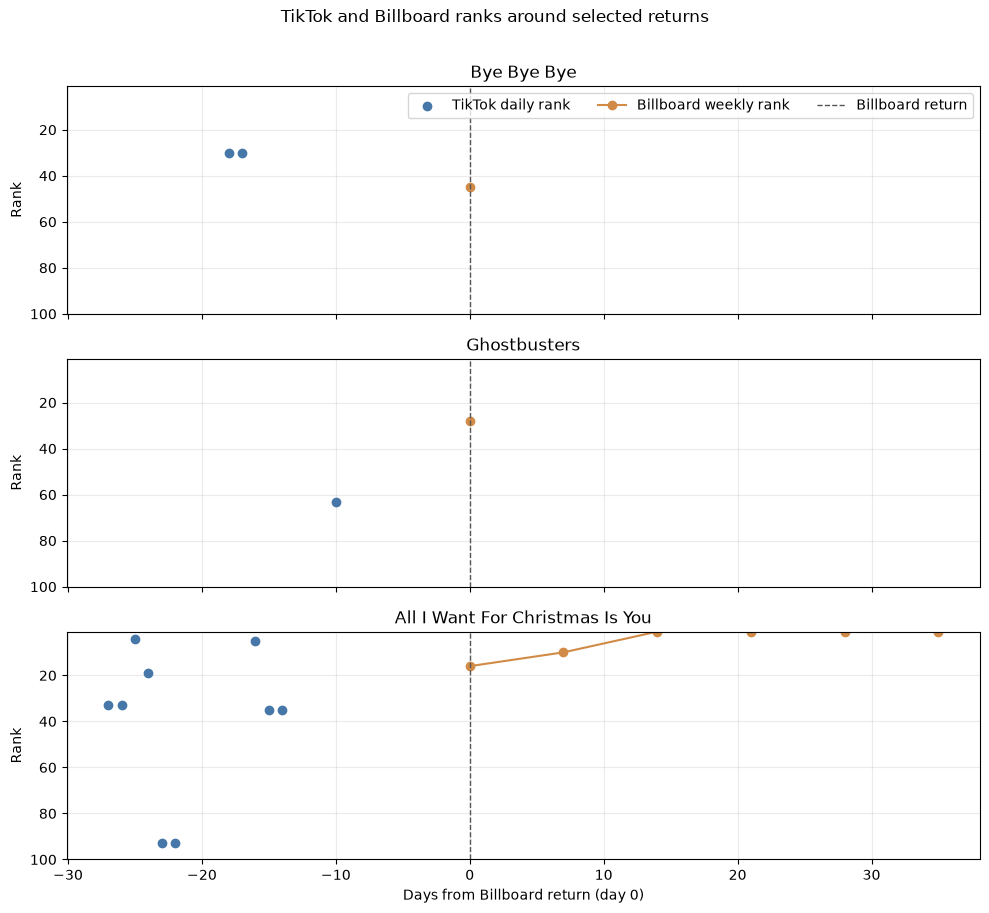

In [51]:
# Select the Billboard returns to compare.
case_specs = [
    {"song": "Bye Bye Bye", "artist": "*NSYNC", "return_date": "2024-08-14"},
    {"song": "Ghostbusters", "artist": "Ray Parker Jr.", "return_date": "2024-11-06"},
    {"song": "All I Want For Christmas Is You", "artist": "Mariah Carey", "return_date": "2024-11-27"},
]

case_rows = []
case_plot_data = []

for case in case_specs:
    return_date = pd.Timestamp(case["return_date"])
    event = billboard_comeback.loc[
        (billboard_comeback["song"] == case["song"]) &
        (billboard_comeback["artist"] == case["artist"]) &
        (billboard_comeback["date"] == return_date)
    ].iloc[0]

    # TikTok activity in the 30 days up to and including the return date.
    title_key = normalize_text(case["song"])
    artist_key = normalize_text(case["artist"])
    tiktok_case = tiktok.loc[
        tiktok["music_title"].map(normalize_text).eq(title_key) &
        tiktok["music_author"].map(normalize_text).eq(artist_key)
    ].copy()
    tiktok_window = tiktok_case.loc[
        tiktok_case["date"].between(return_date - pd.Timedelta(days=30), return_date)
    ]
    tiktok_daily = (tiktok_window.groupby("date", as_index=False)
                    .agg(rank=("rank", "min")))

    # Billboard rank trajectory for eight weeks from the return date.
    billboard_window = (billboard.loc[
        (billboard["song"] == case["song"]) &
        (billboard["artist"] == case["artist"]) &
        billboard["date"].between(return_date, return_date + pd.Timedelta(days=56))
    ].groupby("date", as_index=False).agg(rank=("rank", "min")))

    # Check whether this song also charted near the same calendar date in each
    # of the three prior years. This flags recurring seasonal patterns.
    prior_season_years = 0
    for year in range(return_date.year - 3, return_date.year):
        anniversary = pd.Timestamp(year=year, month=return_date.month, day=return_date.day)
        if billboard.loc[
            (billboard["song"] == case["song"]) &
            (billboard["artist"] == case["artist"]) &
            billboard["date"].between(anniversary - pd.Timedelta(days=21),
                                      anniversary + pd.Timedelta(days=21))
        ].shape[0] > 0:
            prior_season_years += 1

    case_rows.append({
        "song": case["song"],
        "previous_Billboard_date": event["previous_chart_date"],
        "missing_chart_weeks": int(event["missing_chart_weeks"]),
        "Billboard_return_date": return_date,
        "return_rank": int(event["rank"]),
        "TikTok_days_in_prior_30": tiktok_daily["date"].nunique(),
        "best_TikTok_rank_in_prior_30": (
            int(tiktok_daily["rank"].min()) if not tiktok_daily.empty else pd.NA
        ),
        "Billboard_weeks_in_next_8": billboard_window["date"].nunique(),
        "best_Billboard_rank_in_next_8": (
            int(billboard_window["rank"].min()) if not billboard_window.empty else pd.NA
        ),
        "prior_years_with_same_season_charting": f"{prior_season_years}/3",
    })
    case_plot_data.append((case, return_date, tiktok_daily, billboard_window))

case_summary = pd.DataFrame(case_rows)
display(case_summary)

# Plot rank observations relative to the Billboard return date.
fig, axes = plt.subplots(len(case_plot_data), 1, figsize=(10, 9), sharex=True)
for ax, (case, return_date, tiktok_daily, billboard_window) in zip(axes, case_plot_data):
    if not tiktok_daily.empty:
        ax.scatter((tiktok_daily["date"] - return_date).dt.days, tiktok_daily["rank"],
                   color="#4776A8", label="TikTok daily rank", zorder=3)
    if not billboard_window.empty:
        ax.plot((billboard_window["date"] - return_date).dt.days, billboard_window["rank"],
                marker="o", color="#D18B47", label="Billboard weekly rank")
    ax.axvline(0, color="#555555", linestyle="--", linewidth=1, label="Billboard return")
    ax.set_ylim(100, 1)
    ax.set_ylabel("Rank")
    ax.set_title(case["song"])
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Days from Billboard return (day 0)")
axes[0].legend(loc="upper right", ncols=3)
fig.suptitle("TikTok and Billboard ranks around selected returns", y=1.01)
plt.tight_layout()
plt.show()